✅ Mean F0 of original (voiced): 298.1518 Hz
✅ Mean F0 of modified (voiced): 198.7447 Hz
✅ F0 RMSE (before normalization, voiced): 101.0578 Hz
✅ F0 RMSE (after normalization, voiced): 0.0325 (normalized scale)
✅ F0 RMSE (after log conversion, voiced): 0.0500 


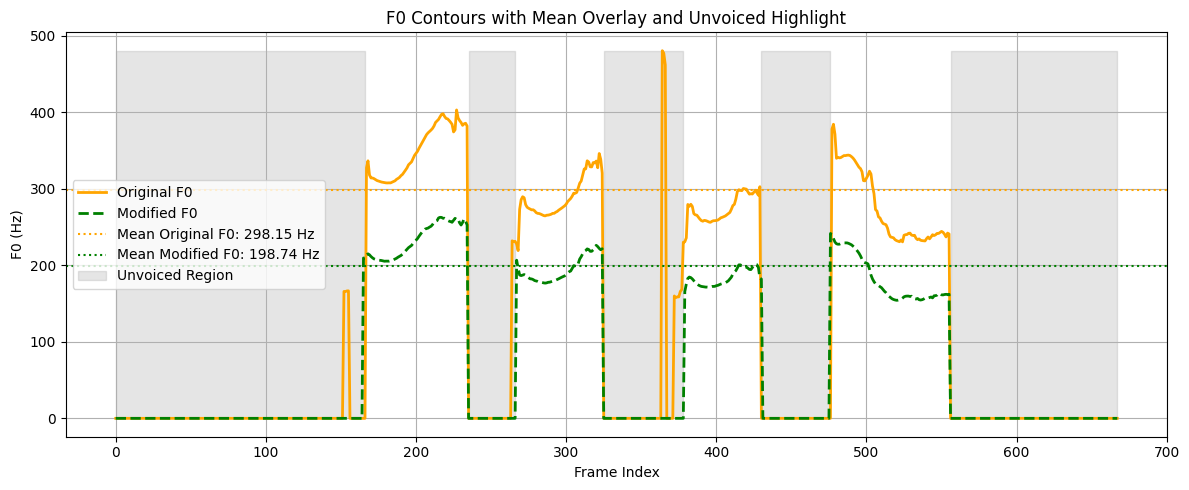

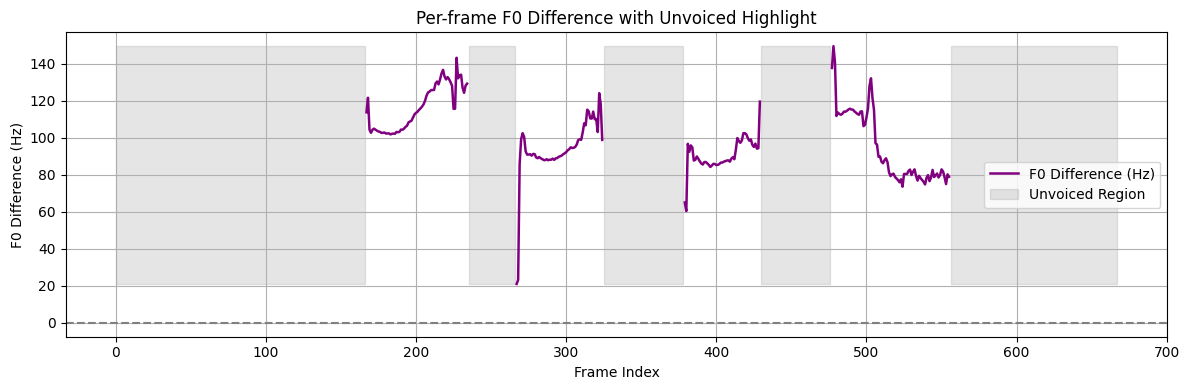

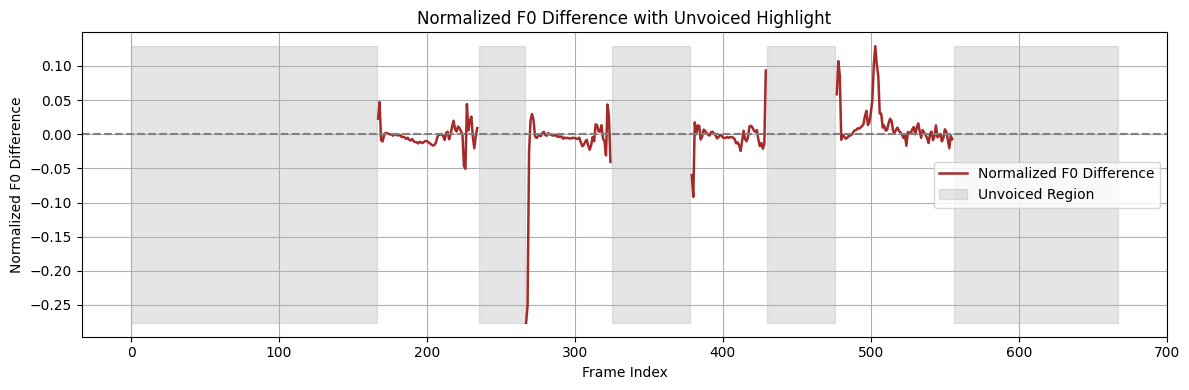

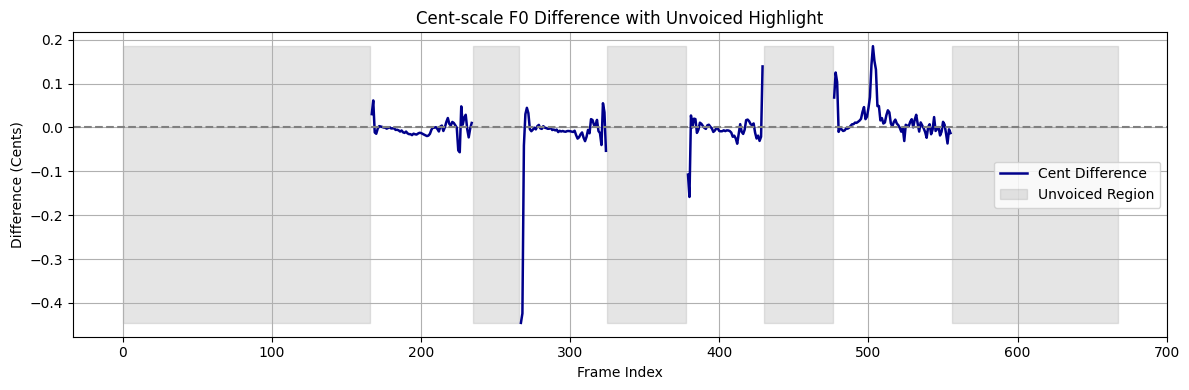

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# === Load pitch data from two files ===
def load_pitch_file(filepath):
    with open(filepath, 'r') as f:
        return np.array([float(line.strip()) for line in f.readlines()])

# === Load F0 data ===
f0_orig = load_pitch_file("/home/drsandipan/Desktop/VTLN-Experiment/Praat_Visulization_Code/Speech_Ocean/Original_Audio_Praat.txt")
f0_mod  = load_pitch_file("/home/drsandipan/Desktop/VTLN-Experiment/Praat_Visulization_Code/Speech_Ocean/Modified_Audio_Praat.txt")

# === Voiced/unvoiced detection ===
voiced_mask = (f0_orig > 0) & (f0_mod > 0)
unvoiced_mask = ~voiced_mask
frame_indices = np.arange(len(f0_orig))

# === Mean F0s from voiced regions ===
f0_voiced_orig = f0_orig[voiced_mask]
f0_voiced_mod  = f0_mod[voiced_mask]

f0_mean_orig = np.mean(f0_voiced_orig)
f0_mean_mod  = np.mean(f0_voiced_mod)

print(f"✅ Mean F0 of original (voiced): {f0_mean_orig:.4f} Hz")
print(f"✅ Mean F0 of modified (voiced): {f0_mean_mod:.4f} Hz")

# === RMSE before normalization ===
f0_diff = f0_voiced_orig - f0_voiced_mod
rmse_f0 = np.sqrt(np.mean(f0_diff ** 2))
print(f"✅ F0 RMSE (before normalization, voiced): {rmse_f0:.4f} Hz")

# === Normalize voiced F0 contours ===
f0_voiced_norm_orig = f0_voiced_orig / f0_mean_orig
f0_voiced_norm_mod  = f0_voiced_mod  / f0_mean_mod

# === RMSE after normalization ===
norm_diff = f0_voiced_norm_orig - f0_voiced_norm_mod
rmse_norm = np.sqrt(np.mean(norm_diff ** 2))
print(f"✅ F0 RMSE (after normalization, voiced): {rmse_norm:.4f} (normalized scale)")

# === Convert to cents (only for voiced frames) ===
cent_voiced_orig =  np.log2(f0_voiced_norm_orig)
cent_voiced_mod  =  np.log2(f0_voiced_norm_mod)
cent_diff = cent_voiced_orig - cent_voiced_mod
rmse_cent = np.sqrt(np.mean(cent_diff ** 2))
print(f"✅ F0 RMSE (after log conversion, voiced): {rmse_cent:.4f} ")

# === Prepare full-length vectors for plotting with NaNs in unvoiced ===
f0_diff_full = np.full_like(f0_orig, np.nan)
f0_diff_full[voiced_mask] = f0_diff

norm_diff_full = np.full_like(f0_orig, np.nan)
norm_diff_full[voiced_mask] = norm_diff

cent_diff_full = np.full_like(f0_orig, np.nan)
cent_diff_full[voiced_mask] = cent_diff

# === Plot 1: Raw F0 contours with means ===
plt.figure(figsize=(12, 5))
plt.plot(f0_orig, color='orange', label="Original F0", linewidth=2)
plt.plot(f0_mod,  color='green', label="Modified F0", linewidth=2, linestyle='--')
plt.axhline(f0_mean_orig, color='orange', linestyle=':', label=f"Mean Original F0: {f0_mean_orig:.2f} Hz")
plt.axhline(f0_mean_mod,  color='green', linestyle=':',  label=f"Mean Modified F0: {f0_mean_mod:.2f} Hz")
plt.fill_between(frame_indices, 0, max(np.max(f0_orig), np.max(f0_mod)), where=unvoiced_mask,
                 color='gray', alpha=0.2, label="Unvoiced Region")
plt.xlabel("Frame Index")
plt.ylabel("F0 (Hz)")
plt.title("F0 Contours with Mean Overlay and Unvoiced Highlight")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# === Plot 2: F0 Difference (Hz) ===
plt.figure(figsize=(12, 4))
plt.plot(f0_diff_full, label="F0 Difference (Hz)", color='purple', linewidth=1.8)
plt.fill_between(frame_indices, np.nanmin(f0_diff), np.nanmax(f0_diff),
                 where=unvoiced_mask, color='gray', alpha=0.2, label='Unvoiced Region')
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel("Frame Index")
plt.ylabel("F0 Difference (Hz)")
plt.title("Per-frame F0 Difference with Unvoiced Highlight")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# === Plot 3: Normalized F0 Difference ===
plt.figure(figsize=(12, 4))
plt.plot(norm_diff_full, label="Normalized F0 Difference", color='brown', linewidth=1.8)
plt.fill_between(frame_indices, np.nanmin(norm_diff), np.nanmax(norm_diff),
                 where=unvoiced_mask, color='gray', alpha=0.2, label='Unvoiced Region')
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel("Frame Index")
plt.ylabel("Normalized F0 Difference")
plt.title("Normalized F0 Difference with Unvoiced Highlight")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# === Plot 4: Cent-scale F0 Difference ===
plt.figure(figsize=(12, 4))
plt.plot(cent_diff_full, label="Cent Difference", color='darkblue', linewidth=1.8)
plt.fill_between(frame_indices, np.nanmin(cent_diff), np.nanmax(cent_diff),
                 where=unvoiced_mask, color='gray', alpha=0.2, label='Unvoiced Region')
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel("Frame Index")
plt.ylabel("Difference (Cents)")
plt.title("Cent-scale F0 Difference with Unvoiced Highlight")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


✅ Saved F0 values to: /home/drsandipan/Desktop/VTLN-Experiment/Praat_Visulization_Code/Speech_Ocean/F0_outputs/
✅ Mean F0 of original (voiced): 299.0755 Hz
✅ Mean F0 of modified (voiced): 198.7917 Hz
✅ F0 RMSE (Hz): 101.6451
✅ F0 RMSE (Normalized): 0.0185
len of f0_voiced_norm_orig 126
✅ F0 RMSE after  log conversion: 30.7580


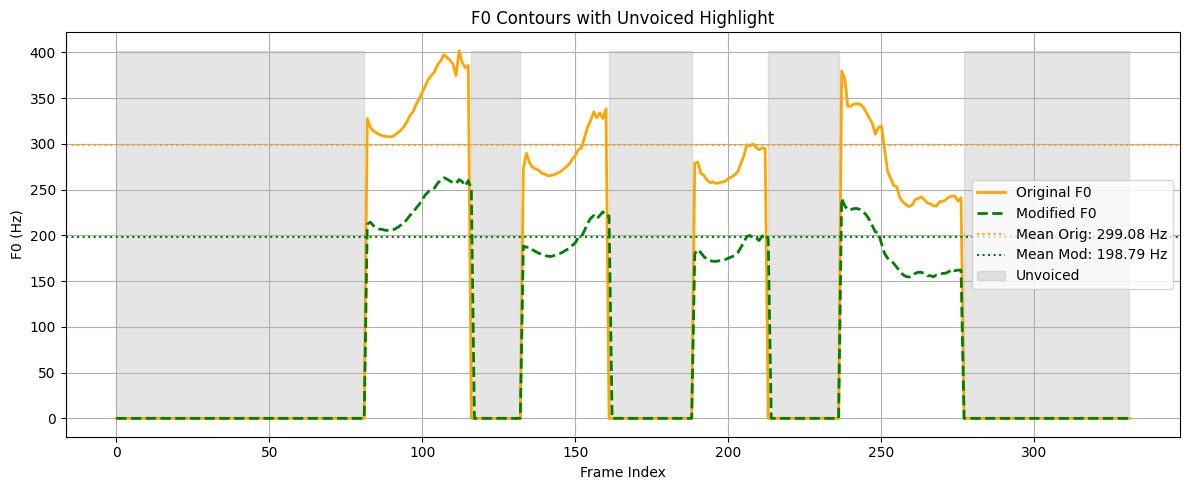

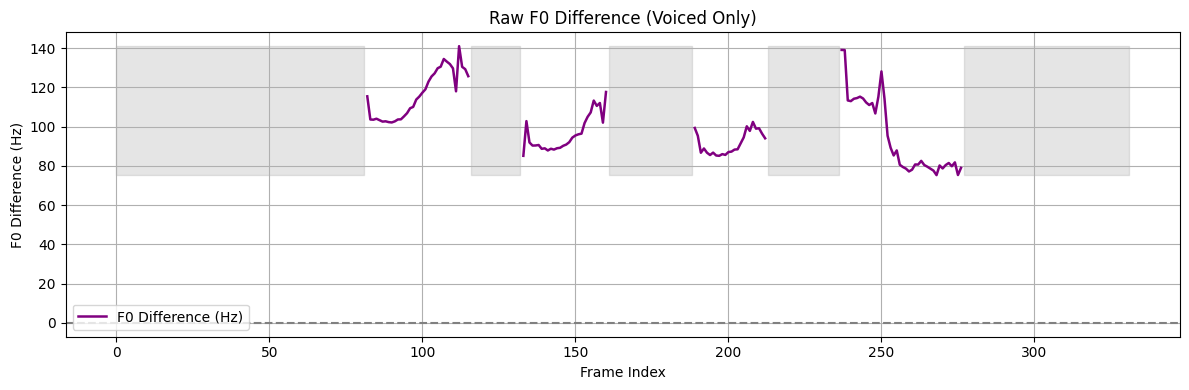

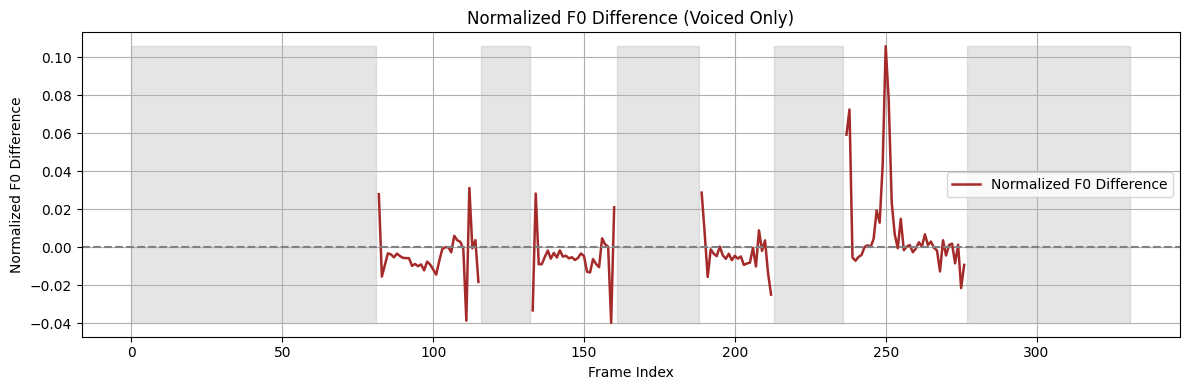

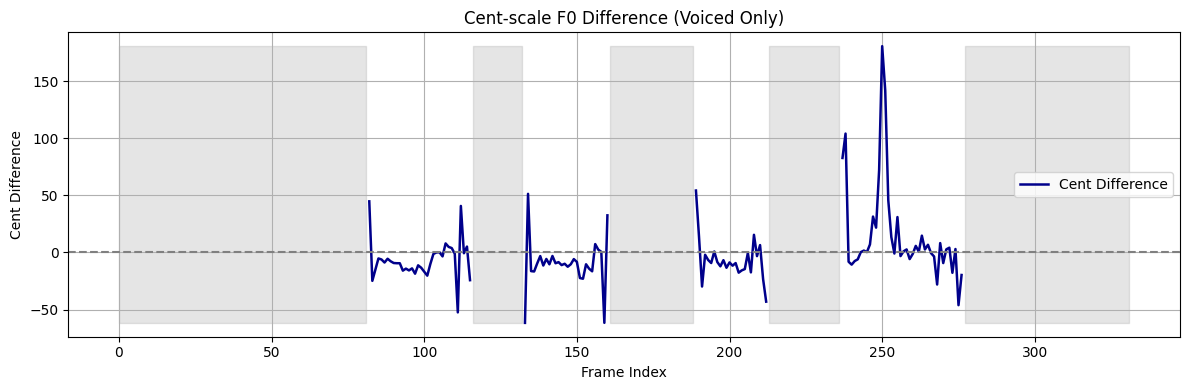

In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
import parselmouth

# === Extract F0 using Parselmouth ===
def extract_f0_parselmouth(wav_path,
                           time_step=0.01,
                           f0_min=150,
                           f0_max=500,
                           silence_threshold=0.03,
                           voicing_threshold=0.5,
                           octave_cost=0.01,
                           octave_jump_cost=0.35,
                           voiced_unvoiced_cost=0.14,
                           max_candidates=15):
    snd = parselmouth.Sound(wav_path)
    pitch = parselmouth.praat.call(
        snd, "To Pitch (ac)...",
        time_step, f0_min, max_candidates, f0_max,
        silence_threshold, voicing_threshold,
        octave_cost, octave_jump_cost, voiced_unvoiced_cost, f0_max
    )
    f0_values = pitch.selected_array['frequency']
    times = pitch.xs()
    voiced_mask = f0_values > 0
    return f0_values, voiced_mask, times, snd


# === File paths ===
original_path = "/home/drsandipan/Desktop/VTLN-Experiment/Praat_Visulization_Code/Speech_Ocean/000010053.wav"
modified_path = "/home/drsandipan/Desktop/VTLN-Experiment/Praat_Visulization_Code/Speech_Ocean/000010053_-7_0.85.wav"

# === Output directory to save F0 files ===
save_dir = "/home/drsandipan/Desktop/VTLN-Experiment/Praat_Visulization_Code/Speech_Ocean/F0_outputs/"
os.makedirs(save_dir, exist_ok=True)

# === Extract F0 ===
f0_orig, mask_orig, times_orig, _ = extract_f0_parselmouth(original_path)
f0_mod,  mask_mod,  times_mod,  _ = extract_f0_parselmouth(modified_path)

# === Save F0 values to text files ===
np.savetxt(os.path.join(save_dir, "000010053_F0_Original.txt"), f0_orig, fmt="%.6f")
np.savetxt(os.path.join(save_dir, "000010053_F0_Modified.txt"), f0_mod, fmt="%.6f")
print(f"✅ Saved F0 values to: {save_dir}")

# === Voiced/unvoiced mask ===
assert len(f0_orig) == len(f0_mod), "Mismatched F0 lengths"
voiced_mask = mask_orig & mask_mod
unvoiced_mask = ~voiced_mask
frame_indices = np.arange(len(f0_orig))

# === F0 values for voiced frames ===
f0_voiced_orig = f0_orig[voiced_mask]
f0_voiced_mod  = f0_mod[voiced_mask]

# === Mean F0s ===
f0_mean_orig = np.mean(f0_voiced_orig)
f0_mean_mod  = np.mean(f0_voiced_mod)

print(f"✅ Mean F0 of original (voiced): {f0_mean_orig:.4f} Hz")
print(f"✅ Mean F0 of modified (voiced): {f0_mean_mod:.4f} Hz")

# === Raw RMSE ===
f0_diff = f0_voiced_orig - f0_voiced_mod
rmse_f0 = np.sqrt(np.mean(f0_diff ** 2))
print(f"✅ F0 RMSE (Hz): {rmse_f0:.4f}")

# === Normalized RMSE ===
f0_voiced_norm_orig = f0_voiced_orig / f0_mean_orig
f0_voiced_norm_mod  = f0_voiced_mod  / f0_mean_mod
norm_diff = f0_voiced_norm_orig - f0_voiced_norm_mod
rmse_norm = np.sqrt(np.mean(norm_diff ** 2))
print(f"✅ F0 RMSE (Normalized): {rmse_norm:.4f}")

# === Cents RMSE ===
print(f"len of f0_voiced_norm_orig {len(f0_voiced_norm_orig)}")
cent_voiced_orig = 1200 * np.log2(f0_voiced_norm_orig)
cent_voiced_mod  = 1200 * np.log2(f0_voiced_norm_mod)
cent_diff = cent_voiced_orig - cent_voiced_mod
rmse_cent = np.sqrt(np.mean(cent_diff ** 2))
print(f"✅ F0 RMSE after  log conversion: {rmse_cent:.4f}")

# === Prepare full arrays for plotting ===
f0_diff_full = np.full_like(f0_orig, np.nan)
norm_diff_full = np.full_like(f0_orig, np.nan)
cent_diff_full = np.full_like(f0_orig, np.nan)
f0_diff_full[voiced_mask]   = f0_diff
norm_diff_full[voiced_mask] = norm_diff
cent_diff_full[voiced_mask] = cent_diff

# === Plot 1: F0 contours ===
plt.figure(figsize=(12, 5))
plt.plot(f0_orig, color='orange', label="Original F0", linewidth=2)
plt.plot(f0_mod, color='green', label="Modified F0", linestyle='--', linewidth=2)
plt.axhline(f0_mean_orig, color='orange', linestyle=':', label=f"Mean Orig: {f0_mean_orig:.2f} Hz")
plt.axhline(f0_mean_mod,  color='green', linestyle=':',  label=f"Mean Mod: {f0_mean_mod:.2f} Hz")
plt.fill_between(frame_indices, 0, max(np.max(f0_orig), np.max(f0_mod)),
                 where=unvoiced_mask, color='gray', alpha=0.2, label="Unvoiced")
plt.xlabel("Frame Index")
plt.ylabel("F0 (Hz)")
plt.title("F0 Contours with Unvoiced Highlight")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# # === Plot 1: F0 contours ===
# plt.figure(figsize=(12, 5))
# plt.plot(f0_voiced_norm_orig, color='orange', label="Original F0", linewidth=2)
# plt.plot(f0_voiced_norm_mod, color='green', label="Modified F0", linestyle='--', linewidth=2)
# plt.fill_between(frame_indices, 0, max(np.max(f0_voiced_norm_orig), np.max(f0_voiced_norm_mod)),
#                  where=unvoiced_mask, color='gray', alpha=0.2, label="Unvoiced")
# plt.xlabel("Frame Index")
# plt.ylabel("F0 (Hz)")
# plt.title("F0 Contours with Unvoiced Highlight")
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# plt.show()



# === Plot 2: Raw F0 Difference (Hz) ===
plt.figure(figsize=(12, 4))
plt.plot(f0_diff_full, label="F0 Difference (Hz)", color='purple', linewidth=1.8)
plt.fill_between(frame_indices, np.nanmin(f0_diff), np.nanmax(f0_diff),
                 where=unvoiced_mask, color='gray', alpha=0.2)
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel("Frame Index")
plt.ylabel("F0 Difference (Hz)")
plt.title("Raw F0 Difference (Voiced Only)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# === Plot 3: Normalized F0 Difference ===
plt.figure(figsize=(12, 4))
plt.plot(norm_diff_full, label="Normalized F0 Difference", color='brown', linewidth=1.8)
plt.fill_between(frame_indices, np.nanmin(norm_diff), np.nanmax(norm_diff),
                 where=unvoiced_mask, color='gray', alpha=0.2)
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel("Frame Index")
plt.ylabel("Normalized F0 Difference")
plt.title("Normalized F0 Difference (Voiced Only)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# === Plot 4: Cent-scale Difference ===
plt.figure(figsize=(12, 4))
plt.plot(cent_diff_full, label="Cent Difference", color='darkblue', linewidth=1.8)
plt.fill_between(frame_indices, np.nanmin(cent_diff), np.nanmax(cent_diff),
                 where=unvoiced_mask, color='gray', alpha=0.2)
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel("Frame Index")
plt.ylabel("Cent Difference")
plt.title("Cent-scale F0 Difference (Voiced Only)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [48]:
import numpy as np

# Step 1: Generate values between 10 and 15
np.random.seed(0)
x = np.random.uniform(10, 15, size=50)
y = x + np.random.normal(0, 0.2, size=50)  # Small noise added

# Step 2: RMSE in Hz
rmse_hz = np.sqrt(np.mean((x - y) ** 2))

# Step 3: RMSE of log values (natural log)
log_rmse = np.sqrt(np.mean((np.log2(x) - np.log2(y)) ** 2))

# Step 4: RMSE in cents (log2 domain)
cent_diff =  (1200 * np.log2(x) - 1200 * np.log2(y))
rmse_cent = np.sqrt(np.mean(cent_diff ** 2))

# Print results
print(f"Original RMSE (Hz):            {rmse_hz:.6f}")
print(f"Log-F0 RMSE (natural log):     {log_rmse:.6f}")
print(f"Cent-scale RMSE:               {rmse_cent:.6f}")


Original RMSE (Hz):            0.188922
Log-F0 RMSE (natural log):     0.022285
Cent-scale RMSE:               26.742394


In [4]:
import numpy as np
12 *  np.log2(198.7917/299.0755)

-7.071026503188402